# Part A — Morphological Gradient preprocessing pipeline

A classical, deterministic preprocessing pipeline for cervical colposcopy
images. This notebook replaces the previous QI-SABP pipeline entirely:
no saliency fusion, no glare masking, no soft masks, no bit allocation,
no dithering, no YCbCr 4:2:0 subsampling, no NLM, no bilateral filtering
and no histogram matching remain. The single preprocessing technique is
the **morphological gradient**.

## What is the morphological gradient here

The morphological gradient of an image is

    grad(x, y) = dilation(img)(x, y) − erosion(img)(x, y)

computed with a 3×3 square structuring element, independently per RGB
channel. Dilation replaces each pixel with the neighbourhood maximum and
erosion with the neighbourhood minimum, so their difference is a local
contrast / edge-magnitude map: it is ~0 on flat regions and large on
vessels, lesion boundaries and texture edges. Unlike linear high-pass
filters (Sobel, Laplacian), it is non-linear, never produces negative
values or ringing, and its output is bounded to [0, 255] by construction.

## Pipeline overview

* Step 1 — Unsharp-mask sharpen (carried over from Step 1, shared with the
  rest of the suite: amount=0.8, ksize=5).
* Step 2 — Morphological-gradient edge enhancement: the per-channel
  gradient map is added back to the sharpened image,
  `out = clip(img + k · grad, 0, 255)` with `k = 1.0`, so the output stays
  a valid colour image in which vessels and lesion boundaries are locally
  contrast-enhanced.

## Output

The pipeline returns an **edge-enhanced uint8 RGB image** with the same
shape as the input. It is NOT a compression scheme: there is no bit budget,
no quantisation and no entropy coding, and the PNG output size is
essentially unchanged. The transform is pointwise, local and fully
deterministic (no random seeds are consumed).

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (that requires the
  multi-technique notebook).
* It does NOT demonstrate a clinical benefit on this single patient.

In [1]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
# ============================================================
import os, glob, time, random, warnings, platform

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter

# scikit-image is REQUIRED by Part B (SSIM + CIE76 dE76 + Lab conversion).
try:
    from skimage.metrics import structural_similarity as _ssim_fn
    from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn
    _SKIMAGE_OK = True
except ImportError as _e:
    _SKIMAGE_OK = False
    print(f"[warn] scikit-image unavailable ({_e}) — Part B needs it for "
          f"SSIM / dE76. Install with: pip install scikit-image")

warnings.filterwarnings('ignore')

# Reproducibility. The morphological gradient itself is deterministic;
# the seed only controls the synthetic fallback dataset.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV / figure artefacts.
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nMorphological Gradient Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


Morphological Gradient Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 — Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Sharpen (Step 1) ----
# This setting comes from Step 1 and is shared across all notebooks in
# the suite (amount=0.8, ksize=5, the Step 1 default). If you change it
# here, change it in the other notebooks and re-run them, otherwise the
# runs are no longer comparable.
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- Morphological gradient (Step 2) ----
# grad = dilate(img, K) - erode(img, K), computed independently per RGB
# channel with the structuring element K below.
#
# MG_KERNEL_SIZE : structuring element side length in px (odd). 3x3 gives
#                  the strongest local edge response on 200x200 frames.
# MG_KERNEL_SHAPE: cv2.MORPH_RECT (square, default) | cv2.MORPH_ELLIPSE |
#                  cv2.MORPH_CROSS. Square is the standard morphological
#                  gradient; ellipse/cross are slightly more isotropic.
# MG_BLEND_K     : out = clip(img + k * grad, 0, 255). k=1.0 adds the full
#                  gradient back (edge enhancement); k=0 would be the
#                  identity; larger k boosts edges harder (and amplifies
#                  more noise).
MG_KERNEL_SIZE = 3
MG_KERNEL_SHAPE = cv2.MORPH_RECT
MG_BLEND_K      = 1.0

# Global flag set later by the loader -- declared here so all downstream
# cells can reference it without NameError.
SYNTHETIC_MODE = False

# ---- Validation batch (Part B) ----
N_PER_CLASS_VALIDATE  = 5
SUBSET_PER_CLASS      = None   # None = load ALL images (recommended)

_shape_name = {cv2.MORPH_RECT: "rect", cv2.MORPH_ELLIPSE: "ellipse",
               cv2.MORPH_CROSS: "cross"}.get(MG_KERNEL_SHAPE, "custom")
print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  morphological gradient: kernel={MG_KERNEL_SIZE}x{MG_KERNEL_SIZE} "
      f"shape={_shape_name} | blend k={MG_BLEND_K}  "
      f"(out = clip(img + k*grad, 0, 255))")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class "
      f"(SUBSET_PER_CLASS={SUBSET_PER_CLASS})")
print(f"  NOTE: no saliency, no bit allocation, no dithering, no chroma")
print(f"        subsampling -- the morphological gradient is the only technique.")

Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  morphological gradient: kernel=3x3 shape=rect | blend k=1.0  (out = clip(img + k*grad, 0, 255))
  validation batch = 5 imgs/class (SUBSET_PER_CLASS=None)
  NOTE: no saliency, no bit allocation, no dithering, no chroma
        subsampling -- the morphological gradient is the only technique.


In [3]:
# ============================================================
# Cell 1.3 -- Sharpen + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Case-insensitive dedupe by filename so the same
    physical file is never loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so the mask-vs-GT
    evaluation has a real target.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")

Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


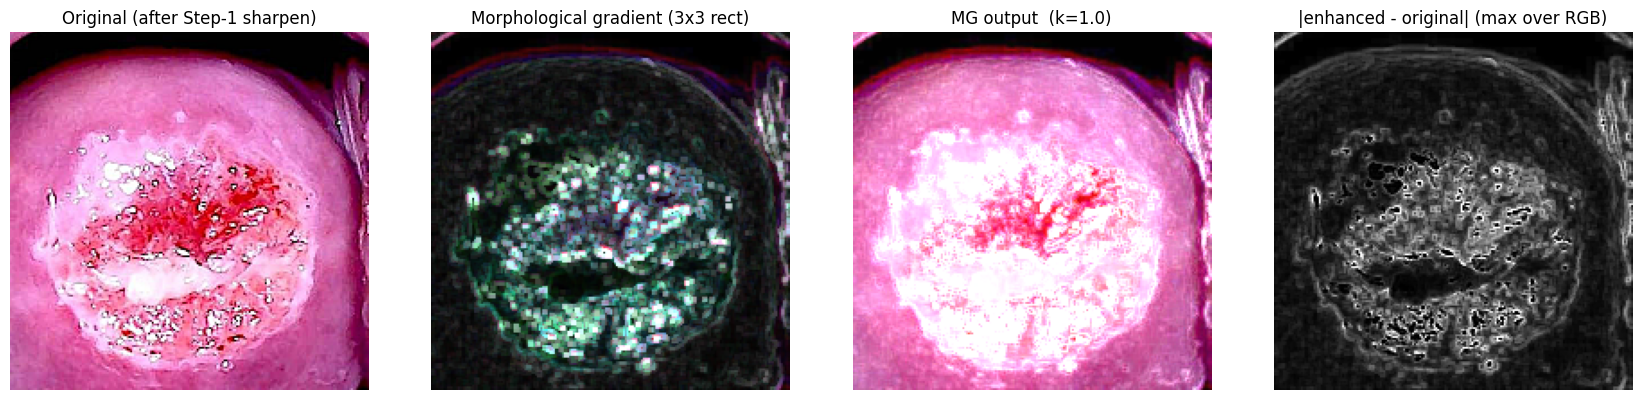

morphgrad_preprocess deterministic: OK | out shape=(200, 200, 3) dtype=uint8 | mean|diff|=34.771


In [4]:
# ============================================================
# Cell 3 -- Morphological Gradient pipeline (Part A technique)
# ============================================================
def _structuring_element(ksize=None, shape=None):
    """Build the structuring element for dilation / erosion."""
    ksize = MG_KERNEL_SIZE if ksize is None else int(ksize)
    shape = MG_KERNEL_SHAPE if shape is None else int(shape)
    if ksize < 1:
        raise ValueError(f"kernel size must be >= 1, got {ksize}")
    return cv2.getStructuringElement(shape, (ksize, ksize))


def morphological_gradient(img_rgb, ksize=None, shape=None):
    """Per-channel morphological gradient: dilate(img) - erode(img).

    Returns a uint8 RGB map that is ~0 on flat regions and large on
    edges / vessel boundaries / texture. Non-linear, deterministic, and
    bounded to [0, 255] by construction (no ringing, unlike linear
    high-pass filters).
    """
    ker = _structuring_element(ksize, shape)
    grad = np.empty_like(img_rgb)
    for ch in range(img_rgb.shape[2]):
        chan = img_rgb[..., ch]
        dil = cv2.dilate(chan, ker)
        ero = cv2.erode(chan, ker)
        grad[..., ch] = cv2.subtract(dil, ero)   # uint8 saturating subtract
    return grad


def morphgrad_preprocess(img_rgb, ksize=None, blend_k=None, shape=None):
    """Morphological-gradient edge enhancement (the Part A technique).

    out = clip(img + blend_k * gradient, 0, 255)

    The gradient map is added back so the output stays a valid colour
    image with locally enhanced vessels and lesion boundaries. Fully
    deterministic; `seed` is not consumed.
    """
    blend_k = MG_BLEND_K if blend_k is None else float(blend_k)
    grad = morphological_gradient(img_rgb, ksize=ksize, shape=shape)
    out = img_rgb.astype(np.float32) + blend_k * grad.astype(np.float32)
    return np.clip(out, 0, 255).astype(np.uint8)


# ---- Visual check: original / gradient map / enhanced -------------------
def show_morphgrad_effect(img_rgb):
    """Show original / morphological gradient / enhanced output."""
    grad = morphological_gradient(img_rgb)
    enhanced = morphgrad_preprocess(img_rgb)
    diff = np.abs(enhanced.astype(np.int16) - img_rgb.astype(np.int16)).max(axis=2)

    fig, ax = plt.subplots(1, 4, figsize=(17, 4))
    ax[0].imshow(img_rgb)
    ax[0].set_title("Original (after Step-1 sharpen)")
    ax[0].axis("off")
    ax[1].imshow(grad)
    ax[1].set_title(f"Morphological gradient ({MG_KERNEL_SIZE}x{MG_KERNEL_SIZE} "
                    f"{_shape_name})")
    ax[1].axis("off")
    ax[2].imshow(enhanced)
    ax[2].set_title(f"MG output  (k={MG_BLEND_K})")
    ax[2].axis("off")
    ax[3].imshow(diff, cmap="gray")
    ax[3].set_title("|enhanced - original| (max over RGB)")
    ax[3].axis("off")
    plt.tight_layout(); plt.show()
    return grad, enhanced


if len(X_raw) > 0:
    _demo_img = X_raw[0]
else:
    _demo_img = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    _demo_img[60:140, 60:140] = np.random.RandomState(SEED + 1).randint(
        160, 255, (80, 80, 3), dtype=np.uint8)
_ = show_morphgrad_effect(_demo_img)

# Determinism check: same input -> bitwise identical output (no RNG inside).
_a = morphgrad_preprocess(_demo_img)
_b = morphgrad_preprocess(_demo_img)
assert np.array_equal(_a, _b), "morphgrad_preprocess is not deterministic"
print(f"morphgrad_preprocess deterministic: OK | out shape={_a.shape} "
      f"dtype={_a.dtype} | mean|diff|="
      f"{np.abs(_a.astype(int) - _demo_img.astype(int)).mean():.3f}")

# Bridge — hand off Morphological Gradient preprocessing to Step 4

Step 4 expects five variables from Steps 1–2:

| Step-4 name | Meaning                                   | Source in this notebook                 |
|-------------|-------------------------------------------|----------------------------------------|
| `X_base`    | (N,200,200,3) uint8 RGB, **sharpened**    | loader's `X_raw` (sharpened by loader) |
| `X_raw`     | (N,200,200,3) uint8 RGB, **resize-only**  | reloaded with `sharpen_it=False`       |
| `image_ids` | unique id per image                       | sequential `img_NNNN`                  |
| `masks`     | clinician lesion masks (OPTIONAL)         | `masks_raw` from the loader            |
| `patient`   | patient id (OPTIONAL)                     | `None`                                 |

The resize-only stack is used only as the source for the field-of-view
(FOV) mask in Part B; the technique itself runs on the sharpened stack.

We also register the technique:

* `MG_DEFAULTS` — empty dict (the pipeline uses fixed module-level config;
  **no tuning on a single patient**).
* `mg_preprocess(img, params, seed) -> uint8 RGB image` — wraps
  `morphgrad_preprocess(img)`. Determinism: the morphological gradient
  consumes no randomness, so `params` and `seed` are accepted for API
  compatibility with the Step 4 validator and ignored. A bitwise
  determinism check runs below.

In [5]:
# ============================================================
# Bridge -- hand off Morphological Gradient preprocessing to Step 4.
# ============================================================

# --- Step-2 sharpened stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # sharpened, 200x200, uint8 RGB
_masks = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Reload the SAME images WITHOUT sharpening -> validator's X_raw ---
#     (used only as the source for the field-of-view mask)
if not SYNTHETIC_MODE:
    _X_unsharp, _y_unsharp, _paths_unsharp, _masks_unsharp, _n_wm, _n_dd = load_dataset(
        DATASET_ROOT, CLASSES,
        size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS,
        sharpen_it=False,                  # <-- resize-only
    )
    if len(_X_unsharp) == 0:               # safety net: fall back to sharpened
        X_raw_unsharp = X_base.copy()
    else:
        X_raw_unsharp = _X_unsharp
        if len(X_raw_unsharp) != len(X_base):
            print(f"[bridge] X_raw_unsharp count ({len(X_raw_unsharp)}) != "
                  f"X_base count ({len(X_base)}); falling back to X_base.")
            X_raw_unsharp = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the
    # sharpen pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_raw_unsharp = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw_unsharp[i] = np.clip(
            X_raw_unsharp[i].astype(np.int32) + np.array([dr, dg, db]),
            0, 255,
        ).astype(np.uint8)

# Step 4 expects the name `X_raw` for the resize-only stack.
X_raw = X_raw_unsharp

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert _masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {_masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

masks = _masks   # pass-through to Step 4 (suite API compatibility)
print(f"Bridge ready | X_base (sharpened) = {X_base.shape} {X_base.dtype} | "
      f"X_raw (resize-only) = {X_raw.shape} {X_raw.dtype} | "
      f"image_ids = {len(image_ids)} (all unique) | masks = {masks.shape} "
      f"({int(masks.any((1,2)).sum())}/{len(masks)} have a lesion) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")

# ---- Morphological-gradient wrapper for Step 4 -------------------------
MG_DEFAULTS = {}

def mg_preprocess(img, params=None, seed=0):
    """Morphological Gradient preprocessing, exposed to the Step 4 validator.

    Signature: mg_preprocess(img_uint8_RGB, params_dict, seed) -> uint8 RGB image.
    `params` and `seed` are accepted for API compatibility but ignored:
    the morphological gradient is deterministic and consumes no randomness,
    and the pipeline uses fixed module-level configuration (no tuning on a
    single patient).
    """
    return morphgrad_preprocess(img)

# Quick smoke test on the first image
_sm = mg_preprocess(X_base[0], MG_DEFAULTS, seed=12345)
assert _sm.shape == X_base[0].shape and _sm.dtype == np.uint8, \
    f"mg_preprocess smoke test failed: got {_sm.shape} {_sm.dtype}"
assert np.array_equal(mg_preprocess(X_base[0], MG_DEFAULTS, seed=12345), _sm), \
    "mg_preprocess is not deterministic for the same seed"
print(f"mg_preprocess() wrapper ready  |  MG_DEFAULTS = {MG_DEFAULTS}  |  "
      f"smoke test on X_base[0]: out shape={_sm.shape} dtype={_sm.dtype}  "
      f"mean|diff|={np.abs(_sm.astype(int)-X_base[0].astype(int)).mean():.3f}")

       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0
Bridge ready | X_base (sharpened) = (128, 200, 200, 3) uint8 | X_raw (resize-only) = (128, 200, 200, 3) uint8 | image_ids = 128 (all unique) | masks = (128, 200, 200) (0/128 have a lesion) | SYNTHETIC_MODE = False
mg_preprocess() wrapper ready  |  MG_DEFAULTS = {}  |  smoke test on X_base[0]: out shape=(200, 200, 3) dtype=uint8  mean|diff|=34.771


# Part B — Validation: 11 metrics per image, inside the FOV only

Single-patient dataset. The frames are NOT independent (dHash clusters).
Descriptive only — no p-values, no robustness or population claims.

**Technique:** MorphGrad — morphological gradient edge enhancement
(3×3 square structuring element, `out = clip(img + k·grad, 0, 255)`,
k = 1.0).

**Metrics:** 11 metrics in 4 groups (fidelity, colour, diagnostic
structure, quality / information). All computed inside the FOV mask only,
per image, against the ORIGINAL (sharpened) image:

| #  | Metric                                    | Group       | Better  |
|----|-------------------------------------------|-------------|---------|
| m1 | PSNR (dB)                                 | fidelity    | up      |
| m2 | SSIM                                      | fidelity    | up      |
| m3 | ΔE76 (CIE76)                              | colour      | down    |
| m4 | a* correlation                            | colour      | up      |
| m5 | \|a* shift\|                              | colour      | down    |
| m6 | Vessel Dice                               | structure   | up      |
| m7 | Edge IoU                                  | structure   | up      |
| m8 | Sharpness ratio (out/in)                  | quality     | neutral |
| m9 | Noise ratio (out/in)                      | quality     | down    |
| m10| Saturation ratio (out/in)                 | quality     | neutral |
| m11| Luma bits (Shannon entropy of output luma)| information | neutral |

**Outputs:** per-image CSV for MorphGrad + an Identity reference row,
cluster-weighted T1 table with 95% bootstrap CI, per-image mean ± std
table, caveats, and two figures (before/after panel, metric bars) saved
to `results/`.

In [6]:
# ============================================================
# Step 4.1 -- Freeze inputs: load frames, FOV masks, cluster ids.
# ============================================================
import hashlib as _hashlib

def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask: largest bright connected region, holes AND frame notches
    filled via convex hull + morphological close."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill (fills notches at the frame edges)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Freeze the inputs from the bridge ----
images = X_base      # (N, 200, 200, 3) uint8 RGB, sharpened (technique input)
images_raw = X_raw   # (N, 200, 200, 3) uint8 RGB, resize-only (FOV source)
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov_step4(images_raw[i]) for i in range(n_images)])

# dHash clustering: groups near-duplicate frames so the aggregation can
# average within a cluster first (frames from one patient are NOT
# independent samples).
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                          for uc in np.unique(cluster_ids)], dtype=int)

# ---- Provenance hash (identifies the exact input stack) -----------------
# NOT asserted against a frozen value: Part A now contains the
# morphological gradient (the input stack is unchanged, but the technique
# and this notebook are new, so there is no historical hash to match).
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
cache_hash = _h.hexdigest()[:12]
print(f"provenance cache_hash = {cache_hash}")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct "
      f"clusters from one patient). All tables say this.")

provenance cache_hash = 12f68b681210
  n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.


In [7]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions (identical in all
#              notebooks of the suite). Computes 10 metrics inside the
#              FOV only; the caller adds m11 (Luma bits).
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    # Frangi filter (scikit-image)
    try:
        from skimage.filters import frangi
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes the Dice coefficient 2*|A∩B|/(|A|+|B|).
    This has more resolution than a pixel-wise correlation (which is
    ~0.99 for any pair of natural images)."""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare pixel mask (V >= 250 AND S <= 25 in HSV)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def luma_entropy_bits(img_rgb, fov_mask):
    """m11 -- Luma bits: Shannon entropy of the luma histogram inside the
    FOV, in bits/px.

    This REPLACES the old allocated-bit-budget definition (QI-SABP had a
    per-pixel bit map; the morphological gradient has none). The entropy
    of the output luma reports how much information the output luma
    channel actually carries; nothing is entropy-coded and no rate is
    controlled.
    """
    f = np.asarray(fov_mask, dtype=bool)
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    if not f.any():
        return float('nan')
    h = np.bincount(g[f].ravel(), minlength=256).astype(np.float64)
    p = h / (h.sum() + 1e-12)
    p = p[p > 0]
    if p.size <= 1:
        return 0.0
    return float(-(p * np.log2(p)).sum())

def step4_validator(original, processed, fov_mask):
    """Compute the 10 image-comparison metrics inside the FOV only.

    Returns a dict with keys m1..m10:
      m1  PSNR (dB)                      up
      m2  SSIM                           up
      m3  dE76 (CIE76)                   down
      m4  a* correlation                 up
      m5  |mean a* shift|                down
      m6  Vessel Dice                    up
      m7  Edge IoU                       up
      m8  Sharpness ratio (out/in)       neutral (0.9-1.1) / higher
      m9  Noise ratio (out/in)           down
      m10 Saturation ratio (out/in)      at most 1

    m11 (Luma bits, Shannon entropy of the output luma inside the FOV) is
    NOT computed here; it is set by the caller via `luma_entropy_bits`.
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                         full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: dE76 (CIE76)
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass in smooth regions
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                   cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular). Measures
    # NEW saturation introduced by the technique, NOT glare removal.
    # A ratio > 1 means the technique adds saturated pixels.
    # Denominator handling: if the input has NO specular pixels inside the
    # FOV (common on synthetic images), the count ratio is undefined; we
    # then report 1.0 when the output also has none (no new saturation)
    # and the raw OUTPUT COUNT otherwise (each new specular pixel counts).
    # When the input HAS specular pixels this is the original out/in ratio
    # (identical to the suite definition for every real colposcopy frame).
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    sp_o_count = float(sp_o[f].sum())
    sp_p_count = float(sp_p[f].sum())
    if sp_o_count == 0:
        m10 = 1.0 if sp_p_count == 0 else sp_p_count
    else:
        m10 = sp_p_count / sp_o_count
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10)

# Metric metadata (key, display name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",       "fidelity",    "up"),
    ("m2",  "SSIM",            "fidelity",    "up"),
    ("m3",  "dE76",            "colour",      "down"),
    ("m4",  "a* corr",         "colour",      "up"),
    ("m5",  "|a* shift|",      "colour",      "down"),
    ("m6",  "Vessel Dice",     "structure",   "up"),
    ("m7",  "Edge IoU",        "structure",   "up"),
    ("m8",  "Sharpness ratio", "quality",     "neutral"),
    ("m9",  "Noise ratio",     "quality",     "down"),
    ("m10", "Saturation ratio","quality",     "neutral"),
    ("m11", "Luma bits",       "information", "neutral"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("step4_validator ready: 10 metrics (m1..m10) + caller-side m11 "
      "(Luma bits = luma entropy).")

step4_validator ready: 10 metrics (m1..m10) + caller-side m11 (Luma bits = luma entropy).


In [8]:
# ============================================================
# Step 4.3 -- Compute the 11 metrics for MorphGrad (+ Identity
#              reference). Write per-image CSVs; cache processed
#              images for the figure cell (no re-runs).
# ============================================================
import os as _os

for _old in glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "MorphGrad"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB

rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    proc = mg_preprocess(orig, MG_DEFAULTS, seed=42 + i)
    m = step4_validator(orig, proc, fov_i)
    m["m11"] = luma_entropy_bits(proc, fov_i)
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_mg = pd.DataFrame(rows)
df_mg.to_csv(f"results_{TECHNIQUE}.csv", index=False)
print(f"Wrote results_{TECHNIQUE}.csv ({len(df_mg)} rows)")
print(f"  Mean luma entropy (m11, output) = {df_mg['m11'].mean():.3f} bits/px")

# ---- Identity reference row (ideal values, not ranked) ------------------
# Identity is a reference only: its dE=0, Dice=1.0, IoU=1.0 are ideal
# values that bound the other rows; it is not a competing technique.
rows_id = []
for i in range(n_images):
    m = step4_validator(images[i], images[i], fov[i])
    m["m11"] = luma_entropy_bits(images[i], fov[i])
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")

  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results_MorphGrad.csv (128 rows)
  Mean luma entropy (m11, output) = 6.686 bits/px
Wrote results_Identity.csv (128 rows)


In [9]:
# ============================================================
# Step 4.4 -- Merge cell: concatenate the technique CSVs (FIXED list,
#              not glob, so stale files cannot leak in). Assert each
#              technique has n_images rows and the same cluster ids;
#              assert no NaNs in any metric column (or list them).
# ============================================================

_csv_names = [
    f"results_{TECHNIQUE}.csv",
    "results_Identity.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list, not glob)")
dfs = []
for f in _csv_names:
    _df = pd.read_csv(f)
    tech = _df["technique"].iloc[0] if len(_df) > 0 else f
    assert len(_df) == n_images, f"{f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{f} cluster ids differ"
    dfs.append(_df)
    print(f"  {f}: {len(_df)} rows, technique = {tech}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

# Hard assert: no NaN in any metric column.
_nan_cols = {}
for col in METRIC_KEYS:
    n_nan = merged[col].isna().sum()
    if n_nan > 0:
        _nan_cols[col] = int(n_nan)
assert len(_nan_cols) == 0, (
    f"NaN values found in metric columns: {_nan_cols}. Inspect the affected "
    f"images (empty FOV, flat regions without smooth-area noise estimate, "
    f"or empty edge maps can produce NaN in rare cases)."
)
print("No NaN values in any metric column (m1..m11).")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")

Reading 2 CSV files (fixed list, not glob)
  results_MorphGrad.csv: 128 rows, technique = MorphGrad
  results_Identity.csv: 128 rows, technique = Identity
Merged: 256 rows, 2 techniques
No NaN values in any metric column (m1..m11).
Techniques: ['Identity', 'MorphGrad']


In [10]:
# ============================================================
# Step 4.5 -- Aggregation: average within each dHash cluster first,
#              then across clusters. 95% CI from a cluster bootstrap
#              (2000 resamples, fixed seed). Also a plain per-image
#              mean +/- std for reference.
#              Label: "within-patient, N clusters, not a population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (2000 resamples).
    Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Cluster-weighted mean + 95% CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")

# Plain per-image mean +/- std (frames are not independent -- this is a
# descriptive spread, not an inferential statistic).
plain_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        row[METRIC_NAMES[mk]] = float(tech_df[mk].mean())
        row[f"{METRIC_NAMES[mk]}_std"] = float(tech_df[mk].std())
    plain_rows.append(row)
plain_df = pd.DataFrame(plain_rows).set_index("technique")

print("Aggregation done (cluster-weighted mean + 95% CI; per-image mean +/- std).")
print(f"  WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.")

Aggregation done (cluster-weighted mean + 95% CI; per-image mean +/- std).
  WITHIN-PATIENT, 7 clusters, NOT a population CI.


In [11]:
# ============================================================
# Step 4.6 -- Print + save the tables:
#   T1  main (cluster-weighted mean [95% CI], 11 metrics)
#   T1b per-image mean +/- std
#   T2  caveats (one line each)
# ============================================================

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

arrow_map = {"up": "^", "down": "v", "neutral": "o"}

# ---- T1 Main -------------------------------------------------------------
print("=" * 110)
print(f"T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, {n_clusters} clusters, "
      f"NOT a population CI)")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 110)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
t1_display = t1_df.rename(columns=t1_headers)
print(t1_display.to_string())
t1_display.to_csv(os.path.join(SAVE_DIR, "summary_T1_cluster_weighted.csv"))

# ---- T1b Per-image mean +/- std -------------------------------------------
print()
print("=" * 110)
print("T1b PER-IMAGE MEAN +/- STD  (descriptive spread; frames not independent)")
print("=" * 110)
t1b_display = plain_df.copy()
t1b_display.columns = [c[:-4] if c.endswith("_std") else c for c in plain_df.columns]
# Interleave mean/std pairs for readability: Metric, Metric_std, ...
_ordered = []
for mk in METRIC_KEYS:
    _ordered.append(METRIC_NAMES[mk])
    _ordered.append(f"{METRIC_NAMES[mk]}_std")
t1b_display = plain_df[_ordered]
print(t1b_display.round(4).to_string())
t1b_display.to_csv(os.path.join(SAVE_DIR, "summary_mean_std.csv"))

# ---- T2 Caveats -------------------------------------------------------------
print()
print("=" * 110)
print("T2 CAVEATS  (one line each)")
print("=" * 110)
caveats = [
    f"Single patient; {n_clusters} distinct frames (dHash); {n_images} frames NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    "Technique: MorphGrad -- morphological gradient edge enhancement, "
    f"{MG_KERNEL_SIZE}x{MG_KERNEL_SIZE} square structuring element, per RGB channel, "
    f"out = clip(img + k*grad, 0, 255), k={MG_BLEND_K}. Deterministic; no RNG.",
    "All metrics are computed inside the convex-hull-filled FOV only (FOV from the "
    "resize-only stack).",
    "dE76 is CIE76 (not CIEDE2000).",
    "Luma bits (m11) is the Shannon entropy of the OUTPUT luma histogram inside the "
    "FOV, in bits/px. It is an information-content report, NOT an allocated bit "
    "budget: nothing is quantised or entropy-coded.",
    "Identity is a reference row only (not ranked): its dE=0, Dice=1.0, IoU=1.0 are "
    "ideal values; its PSNR is the saturating no-error value.",
    "Edge IoU (m7) penalises ANY edge change: an edge-ENHANCING technique adds edge "
    "pixels, so IoU < 1 means new edge structure, not lost anatomy. Read together "
    "with the sharpness ratio (m8).",
    "Vessel Dice (m6): Dice of the top 10% Frangi vessel pixels, 2*|A n B|/(|A|+|B|); "
    "an enhancing technique also shifts the Frangi response, so < 1 is expected.",
    "Sharpness ratio (m8) and Noise ratio (m9) are BOTH expected > 1 for an edge-"
    "enhancing technique: the gradient adds high-frequency energy at edges AND at "
    "noise. If m9 grows much faster than m8, the blend k is over-boosting noise. "
    "If large bright areas clip at 255, flat plateaus form and m8 can drop BELOW "
    "1 -- check m10 and the |diff| figure and reduce k if that happens.",
    "Saturation ratio (m10) is neutral: a value > 1 means the enhancement pushed "
    "bright edge pixels into the clipped specular range (V>=250, S<=25). If the "
    "input frame has NO specular pixels inside the FOV, the raw output count is "
    "reported instead of a ratio (1.0 when the output also has none).",
]
for c in caveats:
    print(f"  - {c}")

T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)
  The 128 frames are NOT independent (7 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
                        PSNR (dB) (^)              SSIM (^)                 dE76 (v)           a* corr (^)          |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (o)
technique                                                                                                                                                                                                                                                             
Identity   148.131 [148.131, 148.131]  1.000 [1.000, 1.000]     0.000 [0.000, 0.000]  1.000 [1.000, 1.000]    0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  7.637 

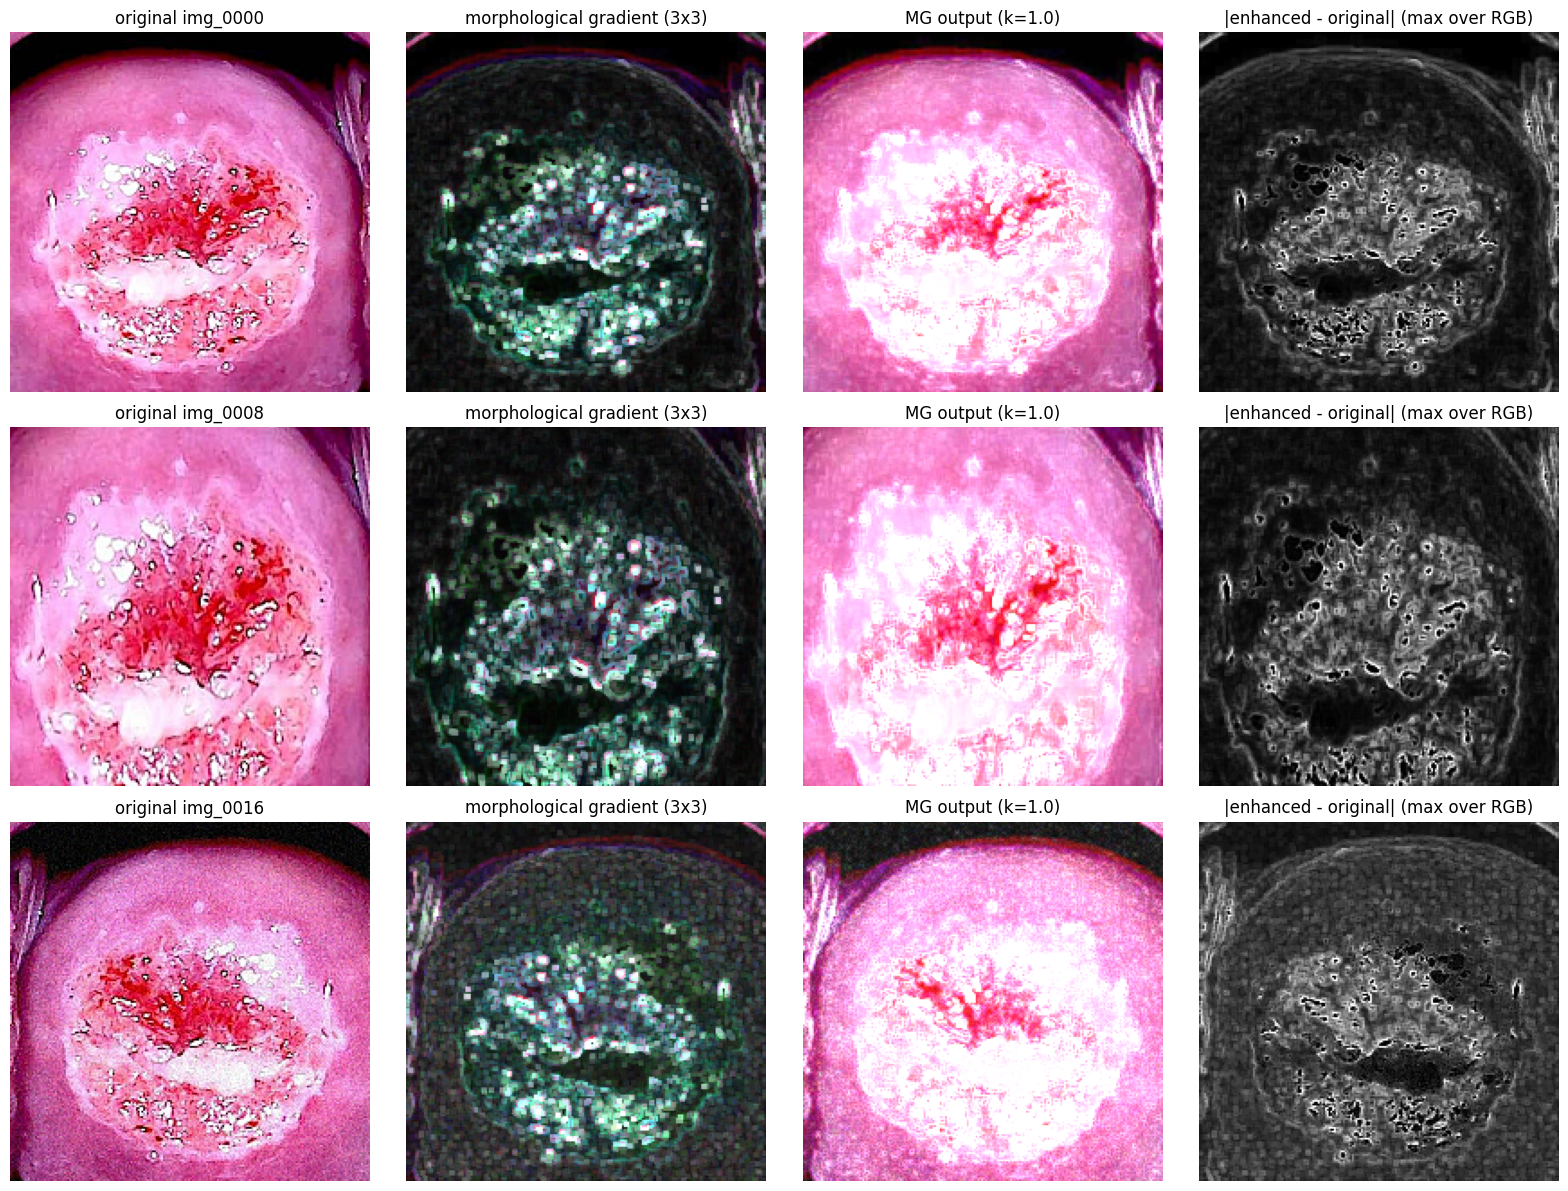

Saved results\fig_morphgrad_before_after.png


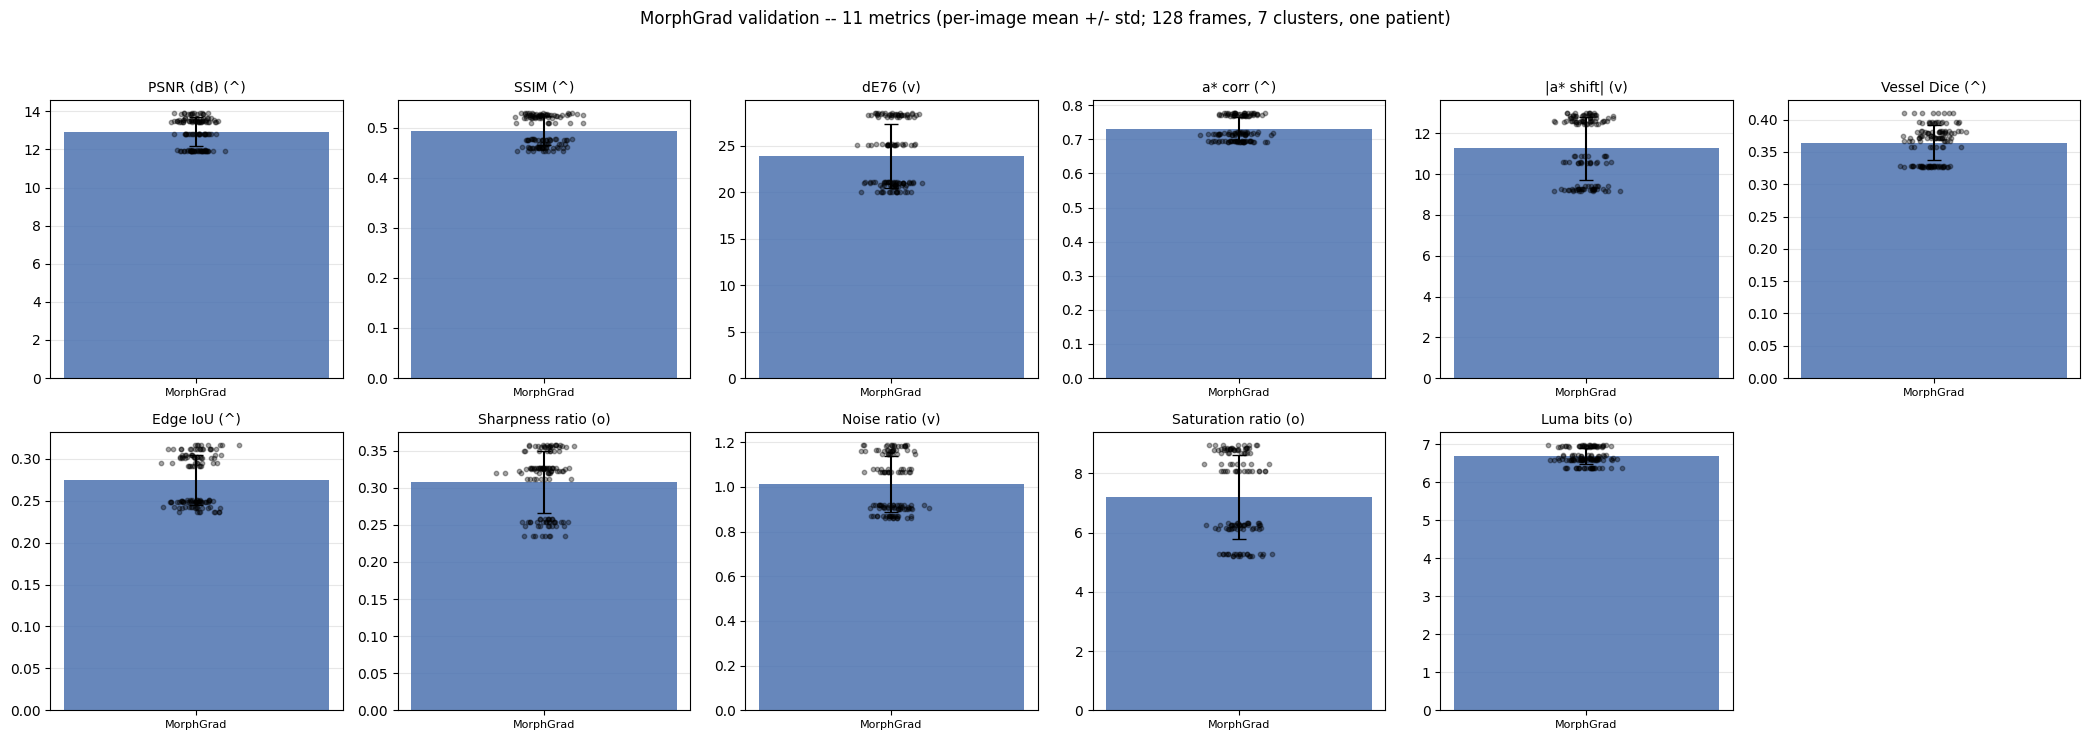

Saved results\fig_metrics.png
All figures and CSVs are in: results/


In [12]:
# ============================================================
# Step 4.7 -- Figures: before/after panel + metric bar charts.
#   Fig 1: for up to 3 distinct (dHash cluster-representative) frames:
#          original | morphological gradient | MG output | |diff|
#   Fig 2: 11 metric bars (per-image mean +/- std, MorphGrad), each
#          with its own scale, with the individual images overlaid.
#   Both figures are saved into results/.
# ============================================================

# ---- Figure 1: before / gradient / after --------------------------------
_rep_idxs = list(cluster_reps[:3])
fig, axes = plt.subplots(len(_rep_idxs), 4, figsize=(16, 4 * len(_rep_idxs)),
                         squeeze=False)
for r, i in enumerate(_rep_idxs):
    orig = images[i]
    proc = processed_cache[(TECHNIQUE, i)]
    grad = morphological_gradient(orig)
    diff = np.abs(proc.astype(np.int16) - orig.astype(np.int16)).max(axis=2)
    axes[r][0].imshow(orig);  axes[r][0].set_title(f"original {image_id[i]}")
    axes[r][1].imshow(grad);  axes[r][1].set_title(
        f"morphological gradient ({MG_KERNEL_SIZE}x{MG_KERNEL_SIZE})")
    axes[r][2].imshow(proc);  axes[r][2].set_title(f"MG output (k={MG_BLEND_K})")
    axes[r][3].imshow(diff, cmap="gray")
    axes[r][3].set_title("|enhanced - original| (max over RGB)")
    for c in range(4):
        axes[r][c].axis("off")
plt.tight_layout()
_fig1_path = os.path.join(SAVE_DIR, "fig_morphgrad_before_after.png")
fig.savefig(_fig1_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {_fig1_path}")

# ---- Figure 2: 11 metric bars ---------------------------------------------
_fig_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 6, figsize=(21, 7.5))
_ax_list = axes.ravel()
for ax, mk in zip(_ax_list, METRIC_KEYS):
    vals = merged.loc[merged["technique"] == TECHNIQUE, mk].astype(float).to_numpy()
    ax.bar([0], [vals.mean()], yerr=[vals.std()], width=0.6, capsize=5,
           color="#4C72B0", alpha=0.85, zorder=2)
    ax.scatter(_fig_rng.normal(0, 0.03, size=len(vals)), vals,
               s=10, color="k", alpha=0.35, zorder=3)
    ax.set_xticks([0])
    ax.set_xticklabels([TECHNIQUE], fontsize=8)
    ax.set_title(f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})",
                 fontsize=10)
    ax.grid(axis="y", alpha=0.3)
_ax_list[len(METRIC_KEYS)].axis("off")
fig.suptitle("MorphGrad validation -- 11 metrics (per-image mean +/- std; "
             f"{n_images} frames, {n_clusters} clusters, one patient)",
             fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.95])
_fig2_path = os.path.join(SAVE_DIR, "fig_metrics.png")
fig.savefig(_fig2_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {_fig2_path}")
print(f"All figures and CSVs are in: {SAVE_DIR}/")

# Reading the 11 metrics for the morphological gradient

**Fidelity (m1, m2).** PSNR and SSIM measure how far the edge-enhanced
output sits from the original overall. For a pure enhancement the values
land between the lossless Identity row and strongly lossy quantisation
pipelines: the gradient only changes pixels near intensity transitions, so
most of the frame is untouched and the mean-based metrics stay high. There
is no absolute "good" number here — the row is a distortion fingerprint of
the kernel size and the blend `k`; if you raise `k`, expect both to drop.

**Colour (m3, m4, m5).** ΔE76 is the mean CIE76 colour difference inside
the FOV. The gradient is computed per RGB channel and clipped, so bright
edge pixels can shift chroma; ΔE76 quantifies exactly that. The a*
correlation and the |a*| shift track the red–green axis, which carries most
of the clinically relevant colour in colposcopy (acetowhite epithelium,
vessel contrast). A correlation near 1 with a shift near 0 means the
technique preserved both the *relative structure* and the *mean* of
redness — the requirement for any downstream colour-based analysis.

**Diagnostic structure (m6, m7).** Vessel Dice is the Dice overlap of the
top-10% Frangi vessel pixels (original vs processed, inside the FOV); Edge
IoU is the IoU of Canny edge maps. For an edge-*enhancing* technique both
typically sit BELOW the Identity values: the processed image has stronger
and additional edge responses, so the binarised sets differ from the
original's. A lower value here therefore means "new edge structure was
added", not "edges were lost" — always read these two together with the
sharpness ratio.

**Quality / information (m8–m11).** The sharpness ratio (Laplacian
variance, out/in) is expected ABOVE 1 — adding the gradient back increases
high-frequency energy, which is the intended effect. One failure mode
exists: when large bright areas clip at 255 the clip creates flat plateaus
whose Laplacian variance is zero, and m8 can drop below 1 — that is a
clipping artefact of a too-large `k` on bright frames, not evidence that
edges were smoothed; check the saturation ratio and the |diff| panel and
reduce `k`. The noise ratio (1.4826·MAD of the high-pass in smooth regions,
out/in) is also expected above 1, because the same amplification applies to
noise; if m9 grows much faster than m8, the blend is over-boosting noise.
The saturation ratio (count of clipped specular pixels, out/in) should stay
near 1; a value above 1 means bright edge pixels are being pushed into the
V≥250, S≤25 specular range by the clip (when the input frame has no
specular pixels at all, the raw output count is reported instead of a
ratio). Luma bits is the Shannon entropy of the output luma histogram
inside the FOV, in bits/px — an information-content report that replaced
the old allocated-bit-budget definition; nothing is quantised or
entropy-coded.

**Caveats carried over from the suite.** Single patient; frames are not
independent (dHash clusters, averaged before aggregation); descriptive
only; CIE76 (not CIEDE2000); every metric is computed inside the
convex-hull-filled FOV of the resize-only stack.